# Probability Distributions and the Central Limit Theorem with Bike Sharing Data

**Course:** AIT 530

**Assignment:** Descriptive Statistics and Probability Distributions

**By:** Yashu Lanki

## Table of Contents

1. Dataset Selection
2. Descriptive Statistics and Visualization
3. Random Variables and Distributions
4. Interpreting a Normal Distribution Graph
5. Calculating Probabilities
6. Applying the Central Limit Theorem
7. Summary of Findings
8. References

## Part 1: Dataset Selection

**Kaggle example.** Before choosing my own dataset, I reviewed Kaggle datasets and notebooks that are used to practice probability and sampling distributions. The code in these notebooks usually follows the same steps:
- It plots a **histogram** of a variable and draws a **fitted normal curve** on top, using the sample mean and standard deviation, to see how well the data matches a normal distribution.
- It uses **scipy.stats** functions (such as `binom.pmf`, `poisson.pmf`, and `norm.cdf`) to calculate the probability of specific outcomes.
- It draws **many random samples** from the data, computes each sample's mean, and plots those means to show the central limit theorem.

I used the same approach in this report, but applied it to a dataset from a repository other than Kaggle, as the assignment requires.

**My dataset.** For this report I used the **Bike Sharing Dataset** from the **UCI Machine Learning Repository** (Fanaee-T, 2013). It records two years (2011–2012) of bike rentals from Capital Bikeshare in Washington, D.C., together with the weather and calendar information for each day. The daily file has **731 days** and the hourly file has **17,379 hours**.

**Why this dataset?**
- It has **both discrete and continuous variables**. The rental counts and calendar flags are discrete, and temperature, humidity, and wind speed are continuous. That lets me try binomial, Poisson, and normal distributions on the same data.
- It has a **skewed variable** (casual riders), which is a good test for the central limit theorem.
- It is **real and relevant to AI**. Bike sharing companies use machine learning to forecast demand and decide where to place bikes, and those models depend on understanding how the data is distributed.

| Variable | Meaning | Type |
|---|---|---|
| `season` | 1 = spring, 2 = summer, 3 = fall, 4 = winter | Discrete (categorical) |
| `holiday` | 1 if the day is a holiday | Discrete (binary) |
| `weekday` | Day of the week (0–6) | Discrete (categorical) |
| `workingday` | 1 if the day is not a weekend or holiday | Discrete (binary) |
| `weathersit` | 1 = clear, 2 = mist/cloudy, 3 = light rain/snow | Discrete (categorical) |
| `temp_c` | Temperature in °C | Continuous |
| `hum_pct` | Humidity in % | Continuous |
| `wind_kmh` | Wind speed in km/h | Continuous |
| `casual` | Rentals by casual (non-member) riders | Discrete (count) |
| `registered` | Rentals by registered members | Discrete (count) |
| `cnt` | Total rentals | Discrete (count) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

day = pd.read_csv("bike_data/day.csv", parse_dates=["dteday"])
hour = pd.read_csv("bike_data/hour.csv", parse_dates=["dteday"])

# The weather columns are stored as normalized values (0 to 1).
# Convert them back to real units using the scale factors from the dataset's Readme.
day["temp_c"] = day["temp"] * 41
day["hum_pct"] = day["hum"] * 100
day["wind_kmh"] = day["windspeed"] * 67

print(f"Daily data:  {day.shape[0]} rows, {day.shape[1]} columns")
print(f"Hourly data: {hour.shape[0]} rows, {hour.shape[1]} columns")
print(f"Missing values in daily data: {day.isna().sum().sum()}")
day[["dteday", "season", "workingday", "weathersit", "temp_c", "hum_pct", "wind_kmh", "casual", "registered", "cnt"]].head()

Daily data:  731 rows, 19 columns
Hourly data: 17379 rows, 17 columns
Missing values in daily data: 0


,dteday,season,workingday,weathersit,temp_c,hum_pct,wind_kmh,casual,registered,cnt
0,2011-01-01,1,0,2,14.11,80.58,10.75,331,654,985
1,2011-01-02,1,0,2,14.90,69.61,16.65,131,670,801
2,2011-01-03,1,1,1,8.05,43.73,16.64,120,1229,1349
3,2011-01-04,1,1,1,8.20,59.04,10.74,108,1454,1562
4,2011-01-05,1,1,1,9.31,43.70,12.52,82,1518,1600


## Part 2: Descriptive Statistics and Visualization

Descriptive statistics summarize a whole column in a few numbers:
- **Mean**: the average value.
- **Median**: the middle value when sorted. It is not pulled by extreme values the way the mean is.
- **Mode**: the most common value. For continuous columns, I rounded to whole numbers first, because exact decimal values almost never repeat.
- **Variance**: the average squared distance from the mean, which measures spread.
- **Standard deviation**: the square root of the variance, so it is in the same units as the data.
- **Skewness**: whether the data has a longer tail on the right (positive) or left (negative).

In [2]:
num_cols = ["temp_c", "hum_pct", "wind_kmh", "casual", "registered", "cnt"]

def describe(s):
    return pd.Series({
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.round().mode().iloc[0],
        "variance": s.var(ddof=1),
        "std": s.std(ddof=1),
        "min": s.min(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "max": s.max(),
        "range": s.max() - s.min(),
        "skewness": s.skew(),
    })

desc = day[num_cols].apply(describe).T
desc

,mean,median,mode,variance,std,min,Q1,Q3,IQR,max,range,skewness
temp_c,20.31,20.43,29.00,56.33,7.51,2.42,13.82,26.87,13.05,35.33,32.90,-0.05
hum_pct,62.79,62.67,54.00,202.86,14.24,0.00,52.00,73.02,21.02,97.25,97.25,-0.07
wind_kmh,12.76,12.13,10.00,26.96,5.19,1.50,9.04,15.63,6.58,34.00,32.50,0.68
casual,848.18,713.00,120.00,"471,450.44",686.62,2.00,315.50,"1,096.00",780.50,"3,410.00","3,408.00",1.27
registered,"3,656.17","3,662.00","1,707.00","2,434,399.96","1,560.26",20.00,"2,497.00","4,776.50","2,279.50","6,946.00","6,926.00",0.04
cnt,"4,504.35","4,548.00","1,096.00","3,752,788.21","1,937.21",22.00,"3,152.00","5,956.00","2,804.00","8,714.00","8,692.00",-0.05


**What the numbers show.**
- **Temperature, humidity, and total rentals** have a mean and median that are almost the same, and their skewness is close to 0. That means they are fairly **symmetric**.
- **Casual riders** have a mean (about 848) well above the median (713), and a skewness of about 1.27. That means they are **right-skewed**: most days have few casual riders, but a few busy days (warm weekends and holidays) have a lot.
- **Wind speed** is also somewhat right-skewed (skewness about 0.68), because calm days are common and very windy days are rare.
- The **mode** of total rentals is less useful than the mean or median, because almost every day has a different count.

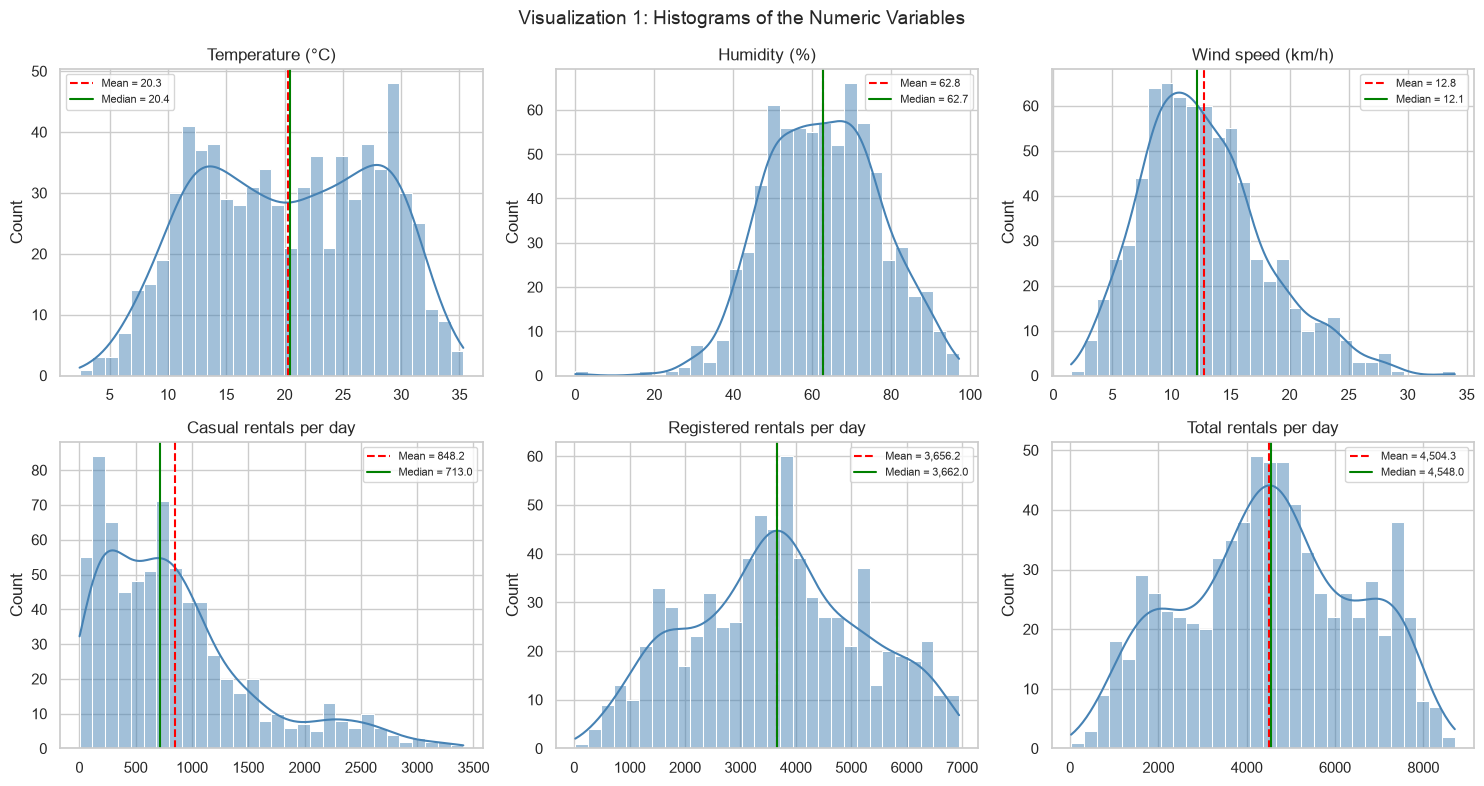

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
labels = {"temp_c": "Temperature (°C)", "hum_pct": "Humidity (%)", "wind_kmh": "Wind speed (km/h)",
          "casual": "Casual rentals per day", "registered": "Registered rentals per day", "cnt": "Total rentals per day"}

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(day[col], bins=30, kde=True, ax=ax, color="steelblue")
    ax.axvline(day[col].mean(), color="red", linestyle="--", label=f"Mean = {day[col].mean():,.1f}")
    ax.axvline(day[col].median(), color="green", linestyle="-", label=f"Median = {day[col].median():,.1f}")
    ax.set_title(labels[col])
    ax.set_xlabel("")
    ax.legend(fontsize=8)

fig.suptitle("Visualization 1: Histograms of the Numeric Variables", fontsize=14)
plt.tight_layout()
plt.show()

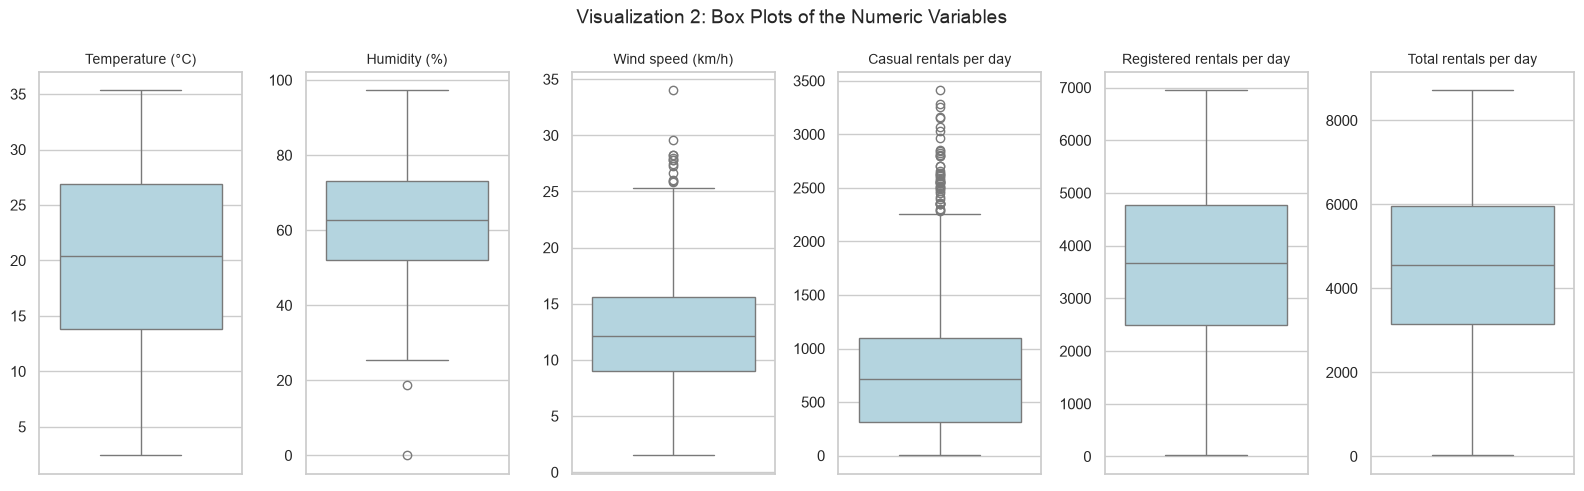

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(16, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=day[col], ax=ax, color="lightblue")
    ax.set_title(labels[col], fontsize=10)
    ax.set_ylabel("")

fig.suptitle("Visualization 2: Box Plots of the Numeric Variables", fontsize=14)
plt.tight_layout()
plt.show()

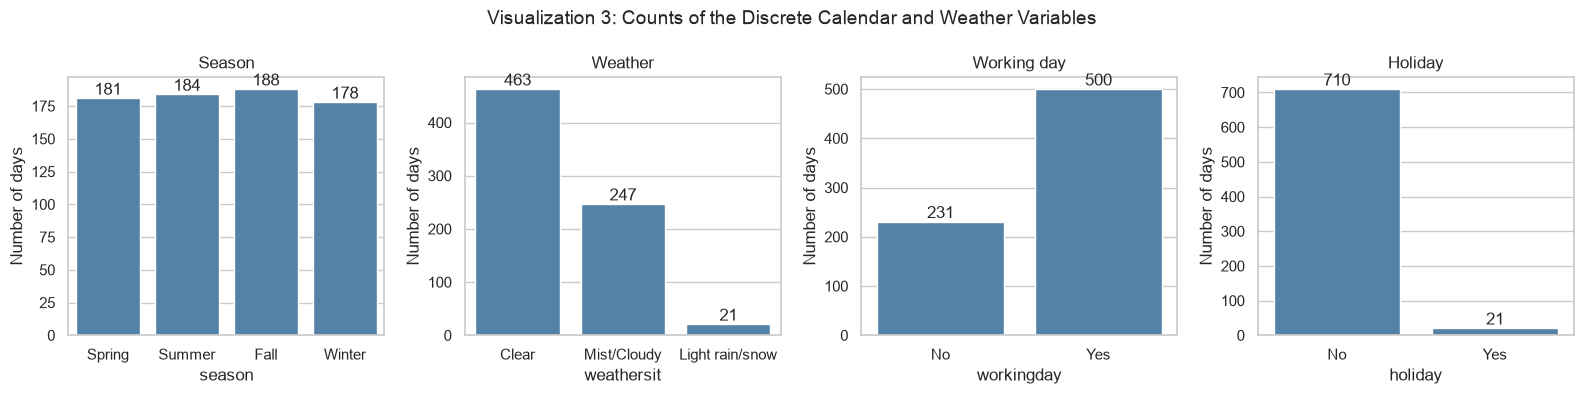

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
cat_info = {
    "season": ("Season", {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}),
    "weathersit": ("Weather", {1: "Clear", 2: "Mist/Cloudy", 3: "Light rain/snow"}),
    "workingday": ("Working day", {0: "No", 1: "Yes"}),
    "holiday": ("Holiday", {0: "No", 1: "Yes"}),
}
for ax, (col, (title, names)) in zip(axes, cat_info.items()):
    counts = day[col].map(names).value_counts().reindex(names.values())
    sns.barplot(x=counts.index, y=counts.values, ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_ylabel("Number of days")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom")

fig.suptitle("Visualization 3: Counts of the Discrete Calendar and Weather Variables", fontsize=14)
plt.tight_layout()
plt.show()

**What the graphs show.**
- The **humidity** histogram is a single, symmetric bell shape. It is the most "normal-looking" column.
- The **temperature** histogram is wide and flat across the middle because the data covers every season. It has no single sharp peak.
- The **casual riders** histogram has a long tail on the right, and its box plot has many outliers above the top whisker. These are the busy, warm weekend days.
- The **box plots** for humidity and wind speed show a few outliers. One day has a humidity of 0%, which is probably a sensor or recording error.
- In the **bar charts**, most days are clear (463 days), about 68% of days are working days, and only 21 days are holidays.

## Part 3: Random Variables and Distributions

A **random variable** is a number that comes from a random process. It is either:
- **Discrete**: it can only take separate, countable values (for example 0, 1, 2, ...).
- **Continuous**: it can take any value in a range, including decimals.

| Variable | Discrete or Continuous | Suitable distribution | Why |
|---|---|---|---|
| `holiday` | Discrete (0/1) | **Bernoulli / Binomial** | Each day is a yes/no trial. Counting holidays across *n* days gives a binomial. |
| `workingday` | Discrete (0/1) | **Bernoulli / Binomial** | Same idea: each day is either a working day or not. |
| `season` | Discrete (4 categories) | **Categorical / Discrete uniform** | Each season covers about a quarter of the year. |
| `weekday` | Discrete (7 categories) | **Discrete uniform** | Each day of the week appears equally often. |
| `weathersit` | Discrete (3 categories) | **Categorical (multinomial)** | Three weather types with different probabilities. |
| `casual`, `registered`, `cnt` | Discrete (counts) | **Poisson** (in theory) | They count events (rentals) in a fixed time period. Real counts are often *overdispersed*, which means a negative binomial fits better (see below). |
| `temp_c` | Continuous | **Normal** (approximately) | Symmetric, but flatter than a normal curve because it mixes all four seasons. |
| `hum_pct` | Continuous | **Normal** | Symmetric, single peak, skewness about 0. |
| `wind_kmh` | Continuous | **Gamma / Log-normal** | Never negative and right-skewed. |

A quick check for the Poisson distribution: in a true Poisson distribution, the **mean equals the variance**. The code below tests that.

In [6]:
count_check = pd.DataFrame({
    "mean": [day["casual"].mean(), day["cnt"].mean(), hour.loc[hour["hr"] == 4, "cnt"].mean()],
    "variance": [day["casual"].var(), day["cnt"].var(), hour.loc[hour["hr"] == 4, "cnt"].var()],
}, index=["casual (per day)", "cnt (per day)", "cnt at 4 AM (per hour)"])
count_check["variance / mean"] = count_check["variance"] / count_check["mean"]
count_check

,mean,variance,variance / mean
casual (per day),848.18,"471,450.44",555.84
cnt (per day),"4,504.35","3,752,788.21",833.15
cnt at 4 AM (per hour),6.35,17.17,2.70


For all three counts, the variance is **larger than the mean**, so the data is **overdispersed**. The daily totals are far too spread out for a Poisson distribution, because weather and season change the demand from day to day. The hourly count at **4 AM** is the closest to Poisson (variance about 2.7× the mean), because it is a small count in a fixed, quiet time window. That is why I use the 4 AM count for the Poisson calculation in Part 5.

## Part 4: Interpreting a Normal Distribution Graph (Humidity)

The **normal distribution** is a bell-shaped curve described by two numbers:
- The **mean (μ)** is the center of the bell.
- The **standard deviation (σ)** is how wide the bell is. The **variance (σ²)** is the same idea, squared.

The **empirical rule** says that for a normal distribution, about **68%** of the values are within 1σ of the mean, **95%** are within 2σ, and **99.7%** are within 3σ.

I used **humidity** because it is the most bell-shaped continuous variable in the dataset.

Mean (μ) = 62.79%   Variance (σ²) = 202.86   Standard deviation (σ) = 14.24%


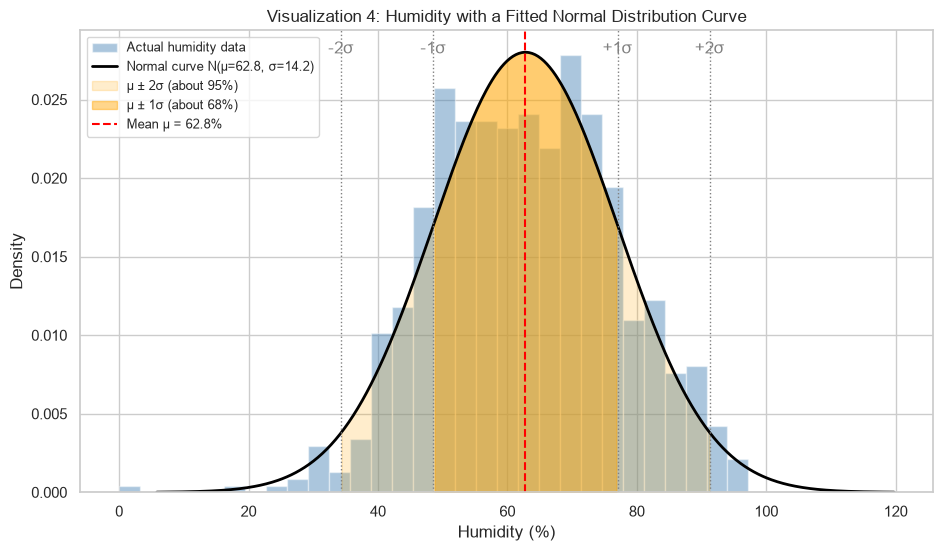

In [7]:
hum = day["hum_pct"]
mu, sigma = hum.mean(), hum.std(ddof=1)
print(f"Mean (μ) = {mu:.2f}%   Variance (σ²) = {sigma**2:.2f}   Standard deviation (σ) = {sigma:.2f}%")

x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
pdf = stats.norm.pdf(x, mu, sigma)

fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(hum, bins=30, density=True, alpha=0.45, color="steelblue", label="Actual humidity data")
ax.plot(x, pdf, color="black", lw=2, label=f"Normal curve N(μ={mu:.1f}, σ={sigma:.1f})")
ax.fill_between(x, pdf, where=(x >= mu - 2 * sigma) & (x <= mu + 2 * sigma), color="orange", alpha=0.2, label="μ ± 2σ (about 95%)")
ax.fill_between(x, pdf, where=(x >= mu - sigma) & (x <= mu + sigma), color="orange", alpha=0.45, label="μ ± 1σ (about 68%)")
ax.axvline(mu, color="red", linestyle="--", label=f"Mean μ = {mu:.1f}%")
for k in [-2, -1, 1, 2]:
    ax.axvline(mu + k * sigma, color="gray", linestyle=":", lw=1)
    ax.text(mu + k * sigma, ax.get_ylim()[1] * 0.95 if k else 0, f"{'+' if k > 0 else ''}{k}σ", ha="center", color="gray")
ax.set_title("Visualization 4: Humidity with a Fitted Normal Distribution Curve")
ax.set_xlabel("Humidity (%)")
ax.set_ylabel("Density")
ax.legend(loc="upper left", fontsize=9)
plt.show()

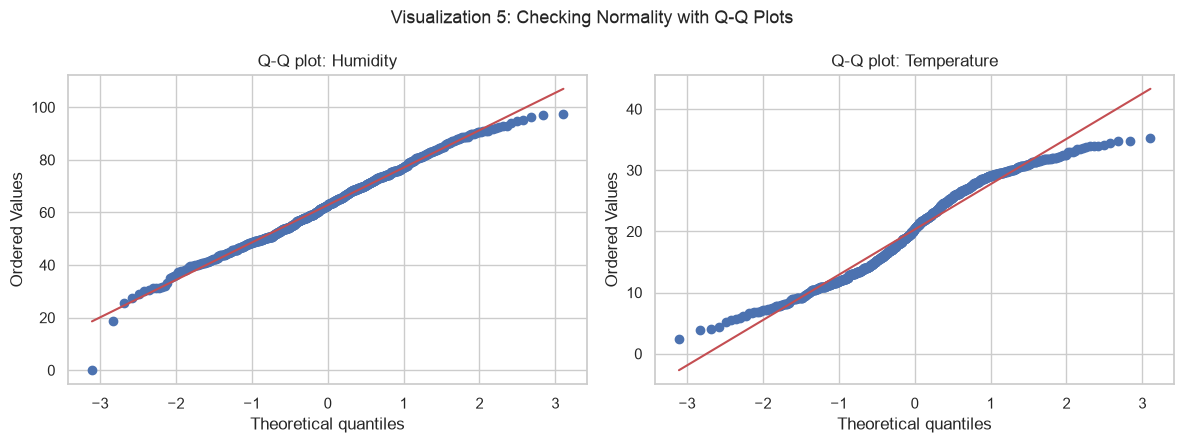

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(day["hum_pct"], dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: Humidity")
stats.probplot(day["temp_c"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: Temperature")
fig.suptitle("Visualization 5: Checking Normality with Q-Q Plots", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation.**
- **Mean (μ ≈ 62.8%)**: the peak of the bell is at the average humidity. The mean and median (62.7%) are almost equal, which is what a symmetric normal curve predicts.
- **Standard deviation (σ ≈ 14.2%)**: a typical day is about 14 percentage points away from the average. The dark shaded band (about 48.5% to 77.0%) is μ ± 1σ, which should hold about 68% of days.
- **Variance (σ² ≈ 202.9)**: it measures the same spread as σ but in squared units (%²), so it is harder to read directly. A larger variance would make the bell wider and flatter, and a smaller one would make it taller and narrower.
- **Fit**: the black normal curve follows the histogram closely. In the Q-Q plot, the humidity points lie almost on the straight line, except for the single 0% day at the bottom-left. In contrast, temperature bends away from the line at both ends, which shows its tails are lighter (flatter) than a normal curve.

## Part 5: Calculating Probabilities

### 5a. Binomial distribution: working days

A **binomial distribution** counts the number of "successes" in *n* independent yes/no trials, each with the same success probability *p*:

$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}$$

Here a trial is one randomly chosen day, and a success is that the day is a **working day**. I estimated *p* from the data, then asked: **if I pick 10 days at random, what is the probability that exactly 7 are working days?**

p (share of working days) = 0.6840
Binomial P(X = 7 of 10)  = 0.2652   |  Simulated from data: 0.2647
Binomial P(X >= 8 of 10) = 0.3413   |  Simulated from data: 0.3400


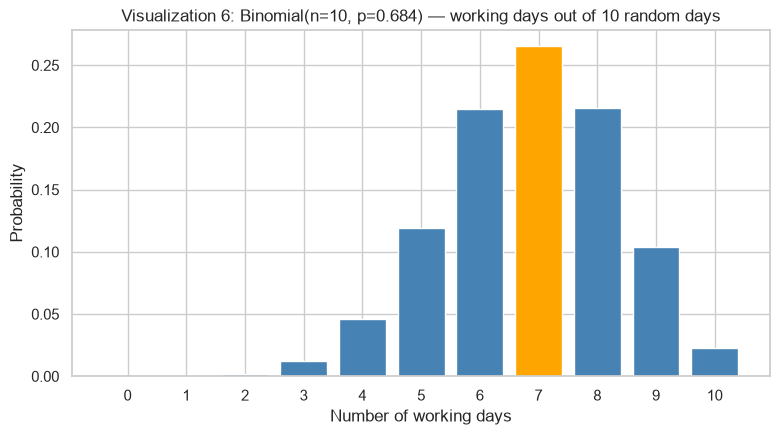

In [9]:
p = day["workingday"].mean()
n, k = 10, 7

p_exact = stats.binom.pmf(k, n, p)
p_at_least_8 = stats.binom.sf(k, n, p)   # sf(k) = P(X > k) = P(X >= 8)

# Check the formula against the real data: draw 10 random days, 100,000 times
rng = np.random.default_rng(42)
draws = rng.choice(day["workingday"].values, size=(100_000, n), replace=True).sum(axis=1)

print(f"p (share of working days) = {p:.4f}")
print(f"Binomial P(X = 7 of 10)  = {p_exact:.4f}   |  Simulated from data: {(draws == 7).mean():.4f}")
print(f"Binomial P(X >= 8 of 10) = {p_at_least_8:.4f}   |  Simulated from data: {(draws >= 8).mean():.4f}")

ks = np.arange(0, n + 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(ks, stats.binom.pmf(ks, n, p), color=["orange" if v == k else "steelblue" for v in ks])
ax.set_title(f"Visualization 6: Binomial(n={n}, p={p:.3f}) — working days out of 10 random days")
ax.set_xlabel("Number of working days")
ax.set_ylabel("Probability")
ax.set_xticks(ks)
plt.show()

**Result.** About 68.4% of days are working days. The probability that **exactly 7 of 10 random days are working days is about 26.5%**, which is the most likely single outcome (the orange bar). The probability of **8 or more** is about 34.1%. The simulation that draws real days from the dataset gives nearly the same numbers, so the binomial model fits well.

### 5b. Poisson distribution: rentals in the 4 AM hour

A **Poisson distribution** counts how many events happen in a fixed time window when events happen independently at an average rate λ:

$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}$$

I used the number of bikes rented in the **4 AM hour**, since it is a small count in a fixed window. **What is the probability that exactly 5 bikes are rented in the 4 AM hour?**

λ (average rentals at 4 AM) = 6.35   (variance = 17.17)
Poisson P(X = 5)   = 0.1502   |  Actual share of 4 AM hours: 0.1119
Poisson P(X <= 3)  = 0.1224   |  Actual share of 4 AM hours: 0.2654
Poisson P(X > 10)  = 0.0590   |  Actual share of 4 AM hours: 0.1463


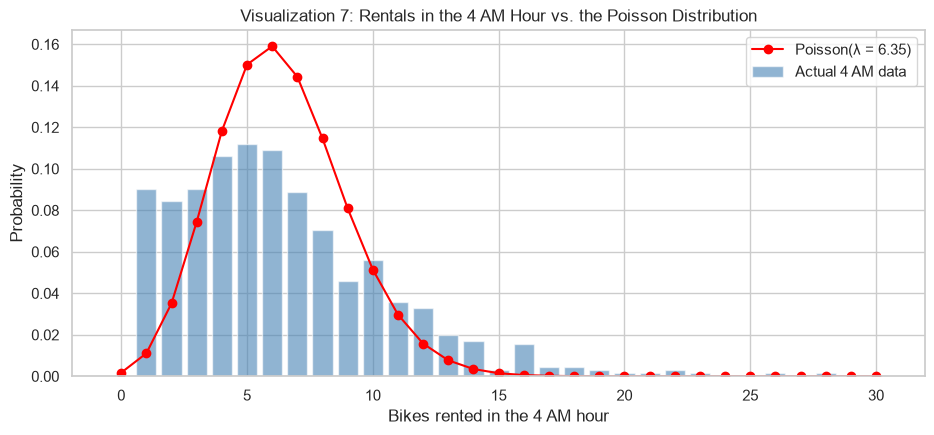

In [10]:
rentals_4am = hour.loc[hour["hr"] == 4, "cnt"]
lam = rentals_4am.mean()

print(f"λ (average rentals at 4 AM) = {lam:.2f}   (variance = {rentals_4am.var():.2f})")
print(f"Poisson P(X = 5)   = {stats.poisson.pmf(5, lam):.4f}   |  Actual share of 4 AM hours: {(rentals_4am == 5).mean():.4f}")
print(f"Poisson P(X <= 3)  = {stats.poisson.cdf(3, lam):.4f}   |  Actual share of 4 AM hours: {(rentals_4am <= 3).mean():.4f}")
print(f"Poisson P(X > 10)  = {stats.poisson.sf(10, lam):.4f}   |  Actual share of 4 AM hours: {(rentals_4am > 10).mean():.4f}")

ks = np.arange(0, 31)
actual = rentals_4am.value_counts(normalize=True).reindex(ks, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(ks, actual.values, alpha=0.6, color="steelblue", label="Actual 4 AM data")
ax.plot(ks, stats.poisson.pmf(ks, lam), "o-", color="red", label=f"Poisson(λ = {lam:.2f})")
ax.set_title("Visualization 7: Rentals in the 4 AM Hour vs. the Poisson Distribution")
ax.set_xlabel("Bikes rented in the 4 AM hour")
ax.set_ylabel("Probability")
ax.legend()
plt.show()

**Result.** On average, about **6.35 bikes** are rented in the 4 AM hour. The Poisson model says the probability of **exactly 5 rentals is about 15.0%**. In the real data, it happened in about 11.2% of 4 AM hours.

The chart shows why the numbers differ: the real data has **more very quiet hours and more busy hours** than the Poisson curve predicts. This is the overdispersion found in Part 3 (variance 17.2 vs. mean 6.35). For example, Poisson says P(X > 10) is about 5.9%, but it really happened in about 14.6% of hours. The Poisson model is a reasonable first estimate, but it **underestimates the extremes**, because the rate itself changes with weather and season. A negative binomial model would fit better.

### 5c. Normal distribution: humidity within one standard deviation

If humidity follows a normal distribution, the probability that a day's humidity falls **within one standard deviation of the mean** is:

$$P(\mu - \sigma \le X \le \mu + \sigma) = \Phi(1) - \Phi(-1) \approx 0.6827$$

where Φ is the standard normal cumulative distribution function.

In [11]:
def within_one_sd(series):
    m, s = series.mean(), series.std(ddof=1)
    theory = stats.norm.cdf(m + s, m, s) - stats.norm.cdf(m - s, m, s)
    actual = series.between(m - s, m + s).mean()
    return pd.Series({"mean": m, "std": s, "lower (μ-σ)": m - s, "upper (μ+σ)": m + s,
                      "normal theory (%)": theory * 100, "actual share (%)": actual * 100})

pd.DataFrame({"Humidity (%)": within_one_sd(day["hum_pct"]),
              "Temperature (°C)": within_one_sd(day["temp_c"])}).T

,mean,std,lower (μ-σ),upper (μ+σ),normal theory (%),actual share (%)
Humidity (%),62.79,14.24,48.55,77.03,68.27,68.13
Temperature (°C),20.31,7.51,12.81,27.82,68.27,59.10


**Result.** Assuming a normal distribution, there is a **68.27%** chance that a day's humidity is between about **48.5% and 77.0%**. In the real data, **68.13%** of days fell in that range, which almost matches the theory.

For comparison, temperature only has about 59% of days within one standard deviation. Its distribution is flatter than a normal curve because it mixes cold winter days and hot summer days. So the normal assumption works well for humidity but should be used with care for temperature.

## Part 6: Applying the Central Limit Theorem

The **central limit theorem (CLT)** says that if you take many random samples of size *n* (usually *n* > 30) and compute each sample's mean, those **sample means will form a normal distribution**, even if the original data is not normal. That distribution of sample means:
- is centered on the **population mean μ**, and
- has a standard deviation called the **standard error**, $SE = \sigma / \sqrt{n}$.

I used **casual riders per day**, because it is clearly **right-skewed** (skewness ≈ 1.27) and not normal. I treated the 731 days as the population, drew **1,000 random samples of n = 40 days**, and computed the mean of each sample.

Population mean μ = 848.18    Population std σ = 686.15    Skewness = 1.264
Mean of the 1000 sample means = 847.37
Std of the sample means      = 107.19
CLT standard error σ/√n      = 108.49
Skewness of the sample means = 0.222


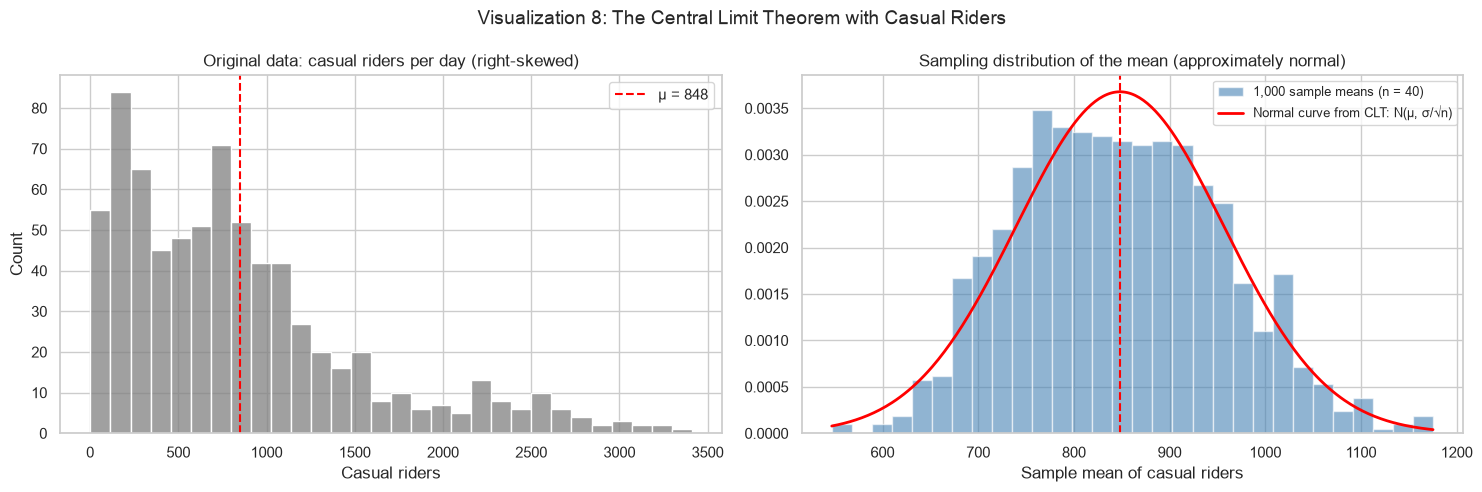

In [12]:
population = day["casual"].values
pop_mean = population.mean()
pop_sd = population.std(ddof=0)

n = 40
n_samples = 1000
rng = np.random.default_rng(42)
samples = rng.choice(population, size=(n_samples, n), replace=True)
sample_means = samples.mean(axis=1)

print(f"Population mean μ = {pop_mean:.2f}    Population std σ = {pop_sd:.2f}    Skewness = {stats.skew(population):.3f}")
print(f"Mean of the {n_samples} sample means = {sample_means.mean():.2f}")
print(f"Std of the sample means      = {sample_means.std(ddof=1):.2f}")
print(f"CLT standard error σ/√n      = {pop_sd / np.sqrt(n):.2f}")
print(f"Skewness of the sample means = {stats.skew(sample_means):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(population, bins=30, ax=axes[0], color="gray")
axes[0].axvline(pop_mean, color="red", linestyle="--", label=f"μ = {pop_mean:.0f}")
axes[0].set_title("Original data: casual riders per day (right-skewed)")
axes[0].set_xlabel("Casual riders")
axes[0].legend()

axes[1].hist(sample_means, bins=30, density=True, alpha=0.6, color="steelblue", label="1,000 sample means (n = 40)")
xs = np.linspace(sample_means.min(), sample_means.max(), 300)
axes[1].plot(xs, stats.norm.pdf(xs, pop_mean, pop_sd / np.sqrt(n)), color="red", lw=2, label="Normal curve from CLT: N(μ, σ/√n)")
axes[1].axvline(pop_mean, color="red", linestyle="--")
axes[1].set_title("Sampling distribution of the mean (approximately normal)")
axes[1].set_xlabel("Sample mean of casual riders")
axes[1].legend(fontsize=9)

fig.suptitle("Visualization 8: The Central Limit Theorem with Casual Riders", fontsize=14)
plt.tight_layout()
plt.show()

To see the CLT happen step by step, I repeated the experiment with different sample sizes. As *n* gets larger, the sample means become **narrower** (smaller standard error) and **more symmetric** (skewness closer to 0).

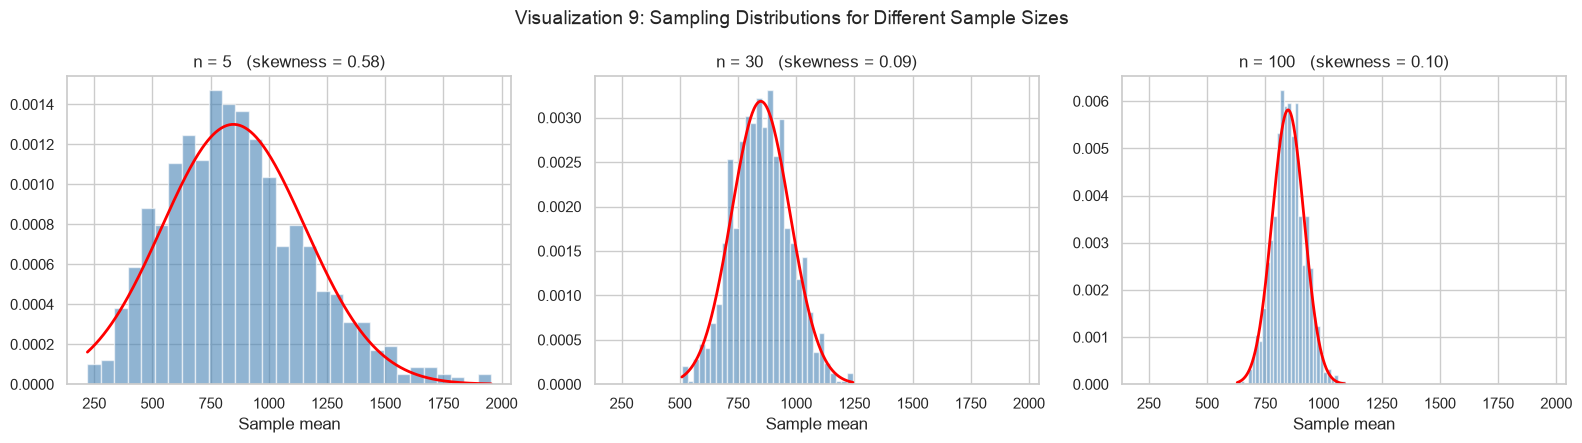

,mean of sample means,std of sample means,σ/√n,skewness
n,,,,
5,861.58,301.09,306.86,0.58
30,851.33,123.31,125.27,0.09
100,850.30,67.67,68.62,0.10


In [13]:
rng = np.random.default_rng(7)
sizes = [5, 30, 100]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
rows = []
for ax, size in zip(axes, sizes):
    means = rng.choice(population, size=(n_samples, size), replace=True).mean(axis=1)
    rows.append({"n": size, "mean of sample means": means.mean(), "std of sample means": means.std(ddof=1),
                 "σ/√n": pop_sd / np.sqrt(size), "skewness": stats.skew(means)})
    ax.hist(means, bins=30, density=True, alpha=0.6, color="steelblue")
    xs = np.linspace(means.min(), means.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, pop_mean, pop_sd / np.sqrt(size)), color="red", lw=2)
    ax.set_title(f"n = {size}   (skewness = {stats.skew(means):.2f})")
    ax.set_xlabel("Sample mean")
fig.suptitle("Visualization 9: Sampling Distributions for Different Sample Sizes", fontsize=14)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("n")

### Using the CLT to make inferences about the population mean

In real life, we usually have only **one sample** and do not know the population mean. Because the CLT says sample means are approximately normal, we can build a **95% confidence interval** from one sample:

$$\bar{x} \pm t_{0.975,\,n-1} \cdot \frac{s}{\sqrt{n}}$$

Below, I built this interval for the first sample, then checked how often the intervals from all 1,000 samples captured the true population mean.

One sample (n = 40): mean = 826.4, 95% CI = (621.8, 1031.0)
True population mean = 848.2 -> captured: True
Share of the 1000 intervals that captured the true mean: 95.0%


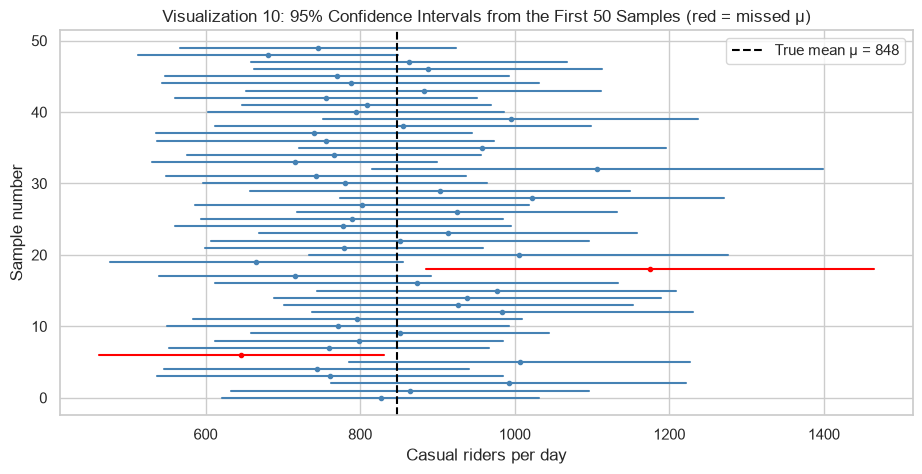

In [14]:
t_crit = stats.t.ppf(0.975, df=n - 1)
sample_sds = samples.std(axis=1, ddof=1)
lower = sample_means - t_crit * sample_sds / np.sqrt(n)
upper = sample_means + t_crit * sample_sds / np.sqrt(n)
captured = (lower <= pop_mean) & (pop_mean <= upper)

print(f"One sample (n = {n}): mean = {sample_means[0]:.1f}, 95% CI = ({lower[0]:.1f}, {upper[0]:.1f})")
print(f"True population mean = {pop_mean:.1f} -> captured: {captured[0]}")
print(f"Share of the {n_samples} intervals that captured the true mean: {captured.mean():.1%}")

fig, ax = plt.subplots(figsize=(11, 5))
show = 50
for i in range(show):
    ax.plot([lower[i], upper[i]], [i, i], color="steelblue" if captured[i] else "red", lw=1.5)
    ax.plot(sample_means[i], i, "o", color="steelblue" if captured[i] else "red", ms=3)
ax.axvline(pop_mean, color="black", linestyle="--", label=f"True mean μ = {pop_mean:.0f}")
ax.set_title(f"Visualization 10: 95% Confidence Intervals from the First {show} Samples (red = missed μ)")
ax.set_xlabel("Casual riders per day")
ax.set_ylabel("Sample number")
ax.legend()
plt.show()

**CLT discussion.**
- **The sample means are normal even though the data is not.** The original casual-rider data is strongly right-skewed (skewness ≈ 1.27), but the 1,000 sample means with n = 40 form a bell shape centered on the true mean (about 848). Their spread (about 107) matches the CLT prediction σ/√n ≈ 108.5.
- **Bigger samples work better.** With n = 5 the sample means are still skewed (skewness ≈ 0.6). At n = 30 they are much closer to normal, and at n = 100 they are almost perfectly symmetric and much narrower. This is why *n* > 30 is a common rule of thumb.
- **Inference about the population mean.** In practice, we only have one sample. The CLT lets us treat that sample's mean as one draw from a normal curve centered on the true mean, so we can attach a margin of error to it. My first sample gave a 95% confidence interval of about 622 to 1,031 casual riders per day, which contains the true mean of 848. Across all 1,000 samples, about **95%** of the intervals captured the true mean, which is exactly what a 95% confidence interval promises.
- **Why this matters for AI.** The CLT is the reason we can report a model's accuracy on a test set with a confidence interval, run A/B tests, and use mini-batch averages in training. It lets us draw reliable conclusions about a whole population from a manageable sample.

## Part 7: Summary of Findings

| Analysis | Key finding |
|---|---|
| Descriptive statistics | Temperature, humidity, and total rentals are fairly symmetric. Casual riders (skew ≈ 1.27) and wind speed (skew ≈ 0.68) are right-skewed. |
| Random variables | Calendar flags and rental counts are discrete. Temperature, humidity, and wind are continuous. |
| Normal curve (humidity) | μ ≈ 62.8%, σ ≈ 14.2%. Humidity closely follows a normal curve. |
| Binomial (working days) | P(exactly 7 of 10 random days are working days) ≈ 26.5%, confirmed by simulation. |
| Poisson (4 AM rentals) | P(exactly 5 rentals) ≈ 15.0% under Poisson vs. 11.2% actual. The data is overdispersed, so Poisson underestimates extremes. |
| Normal (within 1σ) | 68.27% in theory vs. 68.13% actual for humidity. Temperature is only about 59% because its distribution is flatter. |
| Central limit theorem | Sample means of skewed casual-rider data are approximately normal for n = 40, with SE ≈ σ/√n. 95% confidence intervals captured the true mean about 95% of the time. |

**Performance analysis.** Each model was checked against the actual data, not just calculated. The **binomial** and **normal (humidity)** models matched the data very closely. The **Poisson** model was the weakest fit because real rental counts vary more than a Poisson distribution allows. The **CLT** simulation matched its theoretical predictions for the center, the spread, and the 95% coverage. Overall, choosing a distribution should always be followed by checking it against the data, because assumptions like "counts are Poisson" or "temperature is normal" do not always hold.

## Part 8: References

Fanaee-T, H. (2013). *Bike sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

Fanaee-T, H., & Gama, J. (2014). Event labeling combining ensemble detectors and background knowledge. *Progress in Artificial Intelligence, 2*(2), 113–127. https://doi.org/10.1007/s13748-013-0040-3

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021